# Parte Comum: Discussão sobre a granularidade das classes (`NObeyesdad`)

Dataset: Obesity (UCI 544), arquivo tratado `out/parte_comum/obesity_tratado.csv`.

O dataset divide o estado nutricional em **7 classes finas**, seguindo uma subdivisão estendida das faixas de IMC da OMS (separando sobrepeso em níveis I e II e obesidade em tipos I, II e III). Este notebook avalia empiricamente o quanto essas 7 classes são separáveis no espaço de atributos em comparação com agrupamentos mais grossos:

- **7 classes (original):** `Insufficient_Weight`, `Normal_Weight`, `Overweight_Level_I`, `Overweight_Level_II`, `Obesity_Type_I`, `Obesity_Type_II`, `Obesity_Type_III`
- **4 macro-classes (OMS padrão):** `Insufficient_Weight`, `Normal_Weight`, `Overweight` (I + II) e `Obesity` (I + II + III)
- **3 macro-classes (risco amplo):** `Sem_Excesso` (Insufficient + Normal), `Overweight` e `Obesity`

In [ ]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

CAMINHO_DADOS = Path("../../out/parte_comum/obesity_tratado.csv")
PASTA_SAIDA = Path("../../out/parte_comum")
PASTA_SAIDA.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(CAMINHO_DADOS)
COLUNA_CLASSE = "NObeyesdad"
ORDEM_CLASSES = [
    "Insufficient_Weight", "Normal_Weight",
    "Overweight_Level_I", "Overweight_Level_II",
    "Obesity_Type_I", "Obesity_Type_II", "Obesity_Type_III",
]
assert set(df[COLUNA_CLASSE].unique()) == set(ORDEM_CLASSES)

colunas_numericas = df.select_dtypes(include="number").columns.tolist()
print(f"Dataset carregado: {df.shape[0]} linhas x {df.shape[1]} colunas")

Dataset carregado: 2111 linhas x 17 colunas


,silhueta_numericas,silhueta_todas_vars
granularidade,,
7 classes (original),0.0377,0.0070
4 macro-classes (OMS),0.0539,0.0523
3 macro-classes (amplo),0.0655,0.0502


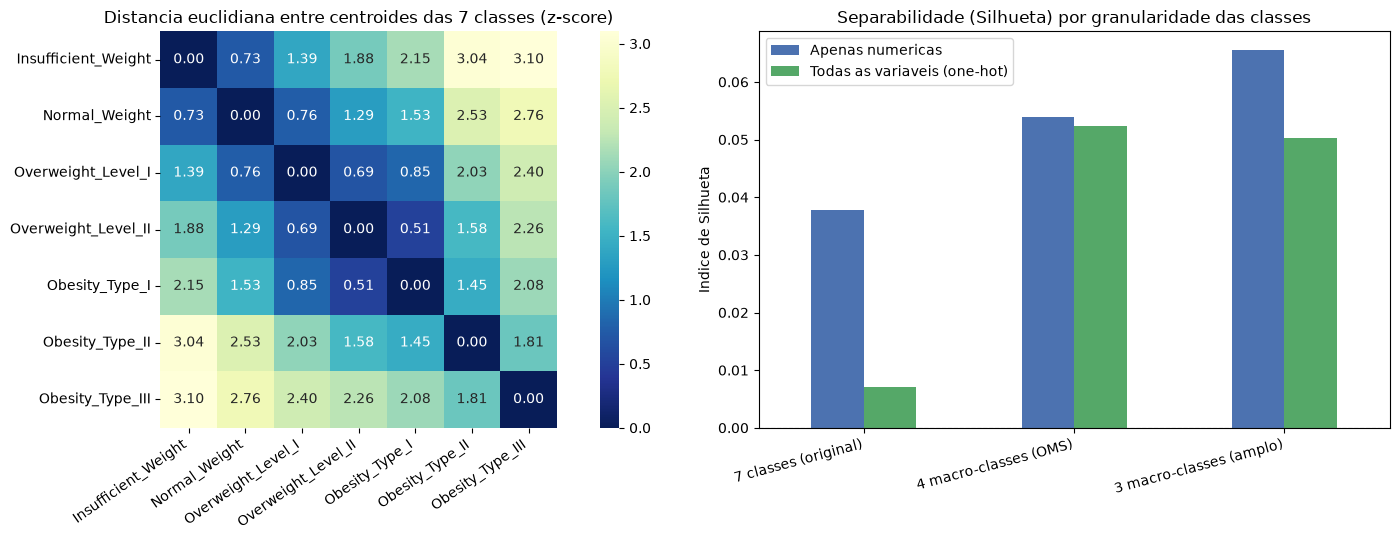

In [3]:
MAPA_4_CLASSES = {
    "Insufficient_Weight": "Insufficient_Weight",
    "Normal_Weight": "Normal_Weight",
    "Overweight_Level_I": "Overweight",
    "Overweight_Level_II": "Overweight",
    "Obesity_Type_I": "Obesity",
    "Obesity_Type_II": "Obesity",
    "Obesity_Type_III": "Obesity",
}

MAPA_3_CLASSES = {
    "Insufficient_Weight": "Sem_Excesso",
    "Normal_Weight": "Sem_Excesso",
    "Overweight_Level_I": "Overweight",
    "Overweight_Level_II": "Overweight",
    "Obesity_Type_I": "Obesity",
    "Obesity_Type_II": "Obesity",
    "Obesity_Type_III": "Obesity",
}

X_num_std = StandardScaler().fit_transform(df[colunas_numericas])
X_all_std = StandardScaler().fit_transform(
    pd.get_dummies(df.drop(columns=[COLUNA_CLASSE]), drop_first=False)
)

centroides = (
    pd.DataFrame(X_num_std, columns=colunas_numericas)
    .assign(classe=df[COLUNA_CLASSE].values)
    .groupby("classe")[colunas_numericas]
    .mean()
    .reindex(ORDEM_CLASSES)
)
matriz_dist = pd.DataFrame(
    np.linalg.norm(centroides.values[:, None, :] - centroides.values[None, :, :], axis=-1),
    index=ORDEM_CLASSES,
    columns=ORDEM_CLASSES,
)

y_7 = df[COLUNA_CLASSE]
y_4 = df[COLUNA_CLASSE].map(MAPA_4_CLASSES)
y_3 = df[COLUNA_CLASSE].map(MAPA_3_CLASSES)

comparacao_gran = pd.DataFrame([
    {
        "granularidade": "7 classes (original)",
        "silhueta_numericas": round(silhouette_score(X_num_std, y_7), 4),
        "silhueta_todas_vars": round(silhouette_score(X_all_std, y_7), 4),
    },
    {
        "granularidade": "4 macro-classes (OMS)",
        "silhueta_numericas": round(silhouette_score(X_num_std, y_4), 4),
        "silhueta_todas_vars": round(silhouette_score(X_all_std, y_4), 4),
    },
    {
        "granularidade": "3 macro-classes (amplo)",
        "silhueta_numericas": round(silhouette_score(X_num_std, y_3), 4),
        "silhueta_todas_vars": round(silhouette_score(X_all_std, y_3), 4),
    },
]).set_index("granularidade")

display(comparacao_gran)

fig, axes = plt.subplots(1, 2, figsize=(16, 5.5), gridspec_kw={"width_ratios": [1.35, 1]})

sns.heatmap(matriz_dist, annot=True, fmt=".2f", cmap="YlGnBu_r", square=True, ax=axes[0])
axes[0].set_title("Distancia euclidiana entre centroides das 7 classes (z-score)")
plt.setp(axes[0].get_xticklabels(), rotation=35, ha="right")

comparacao_gran.plot(kind="bar", ax=axes[1], color=["#4C72B0", "#55A868"])
axes[1].set_title("Separabilidade (Silhueta) por granularidade das classes")
axes[1].set_ylabel("Indice de Silhueta")
axes[1].set_xlabel("")
axes[1].axhline(0, color="gray", linewidth=0.8, linestyle="--", label="_nolegend_")
plt.setp(axes[1].get_xticklabels(), rotation=15, ha="right")
axes[1].legend(labels=["Apenas numericas", "Todas as variaveis (one-hot)"])

fig.tight_layout()
fig.savefig(PASTA_SAIDA / "eda_relacional_granularidade_classes.png", dpi=150, bbox_inches="tight")
plt.show()

## Conclusões sobre a granularidade das classes

1. **Fronteiras artificiais em um fenômeno contínuo:** A variável `NObeyesdad` discretiza uma grandeza contínua (o IMC, $\text{Weight}/\text{Height}^2$) em 7 faixas adjacentes. Como já visto na EDA estrutural (`eda_comum.ipynb`), há sobreposição real de IMC nas bordas — por exemplo, `Overweight_Level_I` (IMC de 22,8 a 28,8) sobrepõe-se tanto a `Normal_Weight` (até 24,9) quanto a `Overweight_Level_II` (25,7 a 30,4), e `Obesity_Type_I` (29,9 a 35,2) encosta em `Obesity_Type_II` (34,0 a 39,8).
2. **Proximidade entre classes intermediárias:** A matriz de distâncias entre centróides mostra que `Overweight_Level_I`, `Overweight_Level_II` e `Obesity_Type_I` possuem hábitos alimentares e de atividade física muito semelhantes (`FCVC`, `NCP`, `CH2O`, `FAF`, `TUE` próximos de zero no z-score). A separação entre `Overweight_Level_I` e `Overweight_Level_II` depende quase exclusivamente de pequenas diferenças em `Weight` e `Age`.
3. **Classes extremas são mais distinguíveis, mas com viés de composição:** `Insufficient_Weight`, `Obesity_Type_II` e `Obesity_Type_III` ficam mais distantes no espaço de atributos. Porém, parte dessa separação vem de padrões específicos da amostra (como `Obesity_Type_II` quase 100% masculina e mais alta, e `Obesity_Type_III` quase 100% feminina com `FCVC` elevado), reforçados pela geração sintética via SMOTE (77% da base).
4. **Impacto direto no agrupamento não supervisionado (K-Means):** Como o K-Means não tem acesso ao rótulo nem à fórmula não-linear do IMC, particionar os dados em $k = 7$ clusters tende a misturar classes adjacentes (especialmente os dois níveis de sobrepeso e `Obesity_Type_I`), derrubando métricas externas como ARI/NMI e gerando baixa Silhueta.
5. **Trade-off da granularidade:**
   - **Manter 7 classes:** preserva o detalhamento clínico (útil para distinguir obesidade severa de sobrepeso leve), mas aumenta o ruído nas fronteiras e dificulta a recuperação exata por algoritmos não supervisionados.
   - **Consolidar em 4 macro-classes da OMS** (`Insufficient_Weight`, `Normal_Weight`, `Overweight`, `Obesity`) **ou 3 macro-classes:** reduz a confusão entre subníveis vizinhos e eleva a coesão interna dos grupos, ao custo de perder a distinção de gravidade dentro de `Obesity` (onde os perfis de tipo II e tipo III são bastante distintos).